# Tabular — Survei Kotor, Multikelas, F1 macro (template utama final)
**Kapan dipakai:** pola soal final GEMASTIK 2024 (penggolongan UKT): kuesioner kotor, kolom
teks bebas, 8 kelas berurutan, kelas langka, metrik F1 macro.

**Langkah:**
1. Profil kolom → cari angka yang tertulis sebagai teks dan ejaan kategori yang berbeda.
2. Bersihkan: "Rp 1.500.000" → angka, "S-1"/"SARJANA" → "S1", teks bebas → n-gram.
3. Bobot kelas seimbang → 5-fold OOF → penskalaan probabilitas per kelas → submission.

OOF dan proba test disimpan (`oof_<Model>.npy`, `test_<Model>.npy`) untuk notebook
`tabular/blending`.

**Data demo:** `ukt_SINTETIS` (dibuat oleh `_alat/buat_data_survei.py`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OrdinalEncoder

## Konfigurasi
Isi `CATEGORY_MAP` setelah melihat `value_counts` di sel profil
(kunci = teks setelah strip + huruf besar).

In [2]:
DATA_FOLDER = "../../../data_latihan/tabular_extra/survei_kotor"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/ukt_SINTETIS_train.csv"
TEST_CSV = f"{DATA_FOLDER}/ukt_SINTETIS_test.csv"

TARGET = "kelas_ukt"
ID_COL = "id"
MONEY_COLS = ["penghasilan_ayah", "penghasilan_ibu"]         # "Rp 1.500.000", "1,5 jt"
NUMBER_TEXT_COLS = ["jumlah_tanggungan", "daya_listrik"]     # "3 orang", "900 VA"
NUM_COLS = ["jumlah_kendaraan"]
CAT_COLS = ["pendidikan_ayah", "status_rumah", "kota", "program_studi", "jalur_masuk",
            "riwayat_beasiswa"]
TEXT_COL = "pekerjaan_ayah"                                  # teks bebas -> feature n-gram
CATEGORY_MAP = {"S-1": "S1", "S 1": "S1", "SARJANA": "S1", "S-2": "S2", "MAGISTER": "S2",
                "S-3": "S3", "S- 3": "S3", "DOKTOR": "S3", "D-3": "D3", "DIPLOMA": "D3",
                "SLTA": "SMA", "SMA/SMK": "SMA", "SMK": "SMA", "SLTP": "SMP",
                "TIDAK TAMAT SD": "SD", "KONTRAK": "SEWA", "NUMPANG ORANG TUA": "MENUMPANG",
                "KIP": "KIP-K", "KIP KULIAH": "KIP-K", "TIDAK ADA": "TIDAK",
                "BELUM PERNAH": "TIDAK", "-": "TIDAK"}
N_FOLD = 5
SEED = 42

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print("train:", train.shape, "| test:", test.shape)
train.sample(5, random_state=SEED)

train: (30380, 14) | test: (7595, 13)


,id,penghasilan_ayah,penghasilan_ibu,pekerjaan_ayah,pendidikan_ayah,jumlah_tanggungan,status_rumah,daya_listrik,jumlah_kendaraan,kota,program_studi,jalur_masuk,riwayat_beasiswa,kelas_ukt
27147,27148,Tidak ada,0,-,SD,NaN,SEWA,1300 VA,1.0,Kupang,Statistika,SNBT,Tidak Ada,0
21900,21901,0,0,tidak bekerja,SLTP,1 orang,SEWA,3.500 VA,1.0,MANADO,Statistika,Mandiri,Belum Pernah,0
22782,22783,"Rp7.522.202,-",Rp 1.232.387,nelayan,SMP,1,menumpang,1300 VA,2.0,Palembang,Pendidikan Bahasa Indonesia,Mandiri,Belum Pernah,5
1122,1123,2.8 juta,Tidak ada,pedagang kecil,Diploma,3 orang,kontrak,450va,0.0,Ambon,Teknik Informatika,SNBT,tidak,3
3353,3354,"4,5 jt",-,Petani,S-2,NaN,Menumpang,450 VA,0.0,Pontianak,Teknik Sipil,SNBT,-,2


## EDA 1 — profil kolom
Cari: angka yang terbaca sebagai teks (`object`), kategori dengan ejaan berbeda, missing.

In [4]:
profile = pd.DataFrame()
profile["tipe"] = train.dtypes
profile["unik"] = train.nunique()
profile["missing_%"] = (train.isna().mean() * 100).round(1)
profile["contoh"] = train.iloc[0]
print(profile)

for col in CAT_COLS + [TEXT_COL]:
    print(train[col].value_counts().head(12), "\n")

                      tipe   unik  missing_%           contoh
id                   int64  30380        0.0                1
penghasilan_ayah    object  17828        0.0          4178989
penghasilan_ibu     object   9760        4.1                0
pekerjaan_ayah      object     41        0.0   pedagang kecil
pendidikan_ayah     object     27        5.1             SLTA
jumlah_tanggungan   object     20        7.8                3
status_rumah        object     11        0.0    MILIK SENDIRI
daya_listrik        object     14        3.0           900 VA
jumlah_kendaraan   float64     11        5.3              3.0
kota                object     50        0.0           Kupang
program_studi       object     15        0.0  Ilmu Komunikasi
jalur_masuk         object      3        0.0          Mandiri
riwayat_beasiswa    object      9        0.0            tidak
kelas_ukt            int64      8        0.0                3
pendidikan_ayah
D3          1802
D-3         1691
Diploma     1674
S-2

## Ubah teks uang menjadi angka
"Rp 1.500.000" / "1,5 jt" / "2.0 juta" → 1500000.0. Selain angka → NaN.

In [5]:
def to_number(text):
    text = str(text).lower()
    text = text.replace("rp", "")
    text = text.replace(",-", "").strip()
    is_million = "jt" in text or "juta" in text
    text = text.replace("juta", "")
    text = text.replace("jt", "").strip()
    if is_million:
        return pd.to_numeric(text.replace(",", "."), errors="coerce") * 1_000_000
    return pd.to_numeric(text.replace(".", "").replace(",", ""), errors="coerce")


# coba pada beberapa contoh
for example in ["Rp 1.500.000", "1,5 jt", "2.0 juta", "Rp1.500.000,-", "-"]:
    print(example, "->", to_number(example))

Rp 1.500.000 -> 1500000
1,5 jt -> 1500000.0
2.0 juta -> 2000000.0
Rp1.500.000,- -> 1500000
- -> nan


## Bersihkan tabel
- Kategori: strip + huruf besar + spasi ganda dirapikan + `CATEGORY_MAP`.
- Uang: `to_number`. Angka-teks ("3 orang"): ambil digitnya saja.
- Dua feature turunan (contoh; sesuaikan dengan data). Outlier tidak dibuang: model pohon tahan.

In [6]:
def clean_table(table):
    table = table.copy()
    for col in CAT_COLS:
        values = table[col].astype(str).str.strip()
        values = values.str.upper()
        values = values.str.replace(r"\s+", " ", regex=True)
        table[col] = values.replace(CATEGORY_MAP)
    for col in MONEY_COLS:
        table[col] = table[col].map(to_number)
    for col in NUMBER_TEXT_COLS:
        digits = table[col].astype(str).str.replace(r"\D", "", regex=True)
        table[col] = pd.to_numeric(digits, errors="coerce")
    table[TEXT_COL] = table[TEXT_COL].fillna("").str.lower()
    table["penghasilan_total"] = table[MONEY_COLS].fillna(0).sum(axis=1)
    people = table["jumlah_tanggungan"].fillna(1)
    table["penghasilan_per_orang"] = table["penghasilan_total"] / people.clip(lower=1)
    return table


train = clean_table(train)
test = clean_table(test)
for col in CAT_COLS:
    print(col, train[col].nunique(), "nilai:", sorted(train[col].unique())[:10])

pendidikan_ayah 8 nilai: ['D3', 'NAN', 'S1', 'S2', 'S3', 'SD', 'SMA', 'SMP']
status_rumah 3 nilai: ['MENUMPANG', 'MILIK SENDIRI', 'SEWA']
kota 25 nilai: ['AMBON', 'BANDUNG', 'BANJARMASIN', 'DENPASAR', 'JAKARTA', 'JAYAPURA', 'KAB. BANYUMAS', 'KAB. BOGOR', 'KAB. DELI SERDANG', 'KAB. GARUT']
program_studi 15 nilai: ['AGROTEKNOLOGI', 'AKUNTANSI', 'BIOLOGI', 'FARMASI', 'HUKUM', 'ILMU KOMUNIKASI', 'KEDOKTERAN', 'MANAJEMEN', 'PENDIDIKAN BAHASA INDONESIA', 'PENDIDIKAN MATEMATIKA']
jalur_masuk 3 nilai: ['MANDIRI', 'SNBP', 'SNBT']
riwayat_beasiswa 2 nilai: ['KIP-K', 'TIDAK']


## EDA 2 — keputusan
Distribusi target (kelas langka?), duplikat, dan kolom yang hampir menentukan target.

In [7]:
target_share = train[TARGET].value_counts(normalize=True)
print(target_share.sort_index().round(3))
without_id = train.drop(columns=ID_COL)
print("duplikat (tanpa id):", without_id.duplicated().sum())
print(train.groupby("riwayat_beasiswa")[TARGET].agg(["mean", "count"]))
print(train.groupby(TARGET)["penghasilan_total"].median())

kelas_ukt
0    0.168
1    0.018
2    0.136
3    0.167
4    0.170
5    0.142
6    0.103
7    0.095
Name: proportion, dtype: float64
duplikat (tanpa id): 0
                      mean  count
riwayat_beasiswa                 
KIP-K             0.334814   2476
TIDAK             3.745520  27904
kelas_ukt
0     1560040.5
1     2076758.0
2     2959510.0
3     4659552.0
4     6800000.0
5     9837369.0
6    14400000.0
7    25400000.0
Name: penghasilan_total, dtype: float64


## Siapkan X, y, fold
`CLASSES` = urutan kolom hasil `predict_proba`.

In [8]:
FEATURE_NUM = MONEY_COLS + NUMBER_TEXT_COLS + NUM_COLS
FEATURE_NUM = FEATURE_NUM + ["penghasilan_total", "penghasilan_per_orang"]
X = train[FEATURE_NUM + CAT_COLS + [TEXT_COL]]
y = train[TARGET]
CLASSES = np.sort(y.unique())
folds = StratifiedKFold(N_FOLD, shuffle=True, random_state=SEED)

## Model
Semua pilihan memakai bobot kelas seimbang, seperti tim juara 2024.
Pilih SATU model: hapus `#` di baris yang ingin dipakai, beri `#` pada baris lain.

In [9]:
text_encoder = CountVectorizer(ngram_range=(1, 3), min_df=5, max_features=300, binary=True)
cat_encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
preprocess = ColumnTransformer([
    ("num", "passthrough", FEATURE_NUM),
    ("cat", cat_encoder, CAT_COLS),
    ("teks", text_encoder, TEXT_COL),
], sparse_threshold=0)

model = LGBMClassifier(n_estimators=400, learning_rate=0.05, class_weight="balanced",
                       random_state=SEED, verbose=-1)
# model = CatBoostClassifier(iterations=800, auto_class_weights="Balanced", random_seed=SEED,
#                            verbose=0, allow_writing_files=False)
# model = RandomForestClassifier(n_estimators=500, class_weight="balanced", min_samples_leaf=3,
#                                random_state=SEED, n_jobs=-1)
# model = ExtraTreesClassifier(n_estimators=500, class_weight="balanced", min_samples_leaf=3,
#                              random_state=SEED, n_jobs=-1)

pipe = make_pipeline(preprocess, model)
MODEL_NAME = type(model).__name__   # dipakai untuk nama file oof_/test_
print(MODEL_NAME)

LGBMClassifier


## Evaluasi — 5-fold OOF
Tiap baris train diprediksi oleh model yang tidak melihatnya. Skor ini lebih bisa dipercaya
daripada public leaderboard.

LGBMClassifier F1 macro OOF: 0.4703
              precision    recall  f1-score   support

           0       0.87      0.84      0.85      5116
           1       0.10      0.09      0.09       550
           2       0.47      0.56      0.51      4122
           3       0.41      0.38      0.40      5078
           4       0.41      0.36      0.38      5172
           5       0.40      0.39      0.39      4317
           6       0.40      0.44      0.42      3132
           7       0.69      0.73      0.71      2893

    accuracy                           0.52     30380
   macro avg       0.47      0.47      0.47     30380
weighted avg       0.51      0.52      0.51     30380



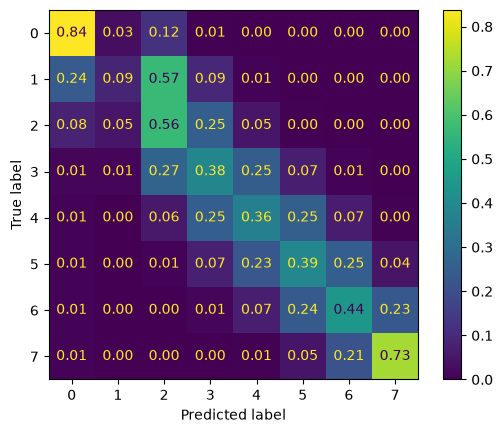

In [10]:
oof = cross_val_predict(pipe, X, y, cv=folds, method="predict_proba")
oof_predictions = CLASSES[oof.argmax(axis=1)]
oof_score = f1_score(y, oof_predictions, average="macro")
print(MODEL_NAME, "F1 macro OOF:", round(oof_score, 4))
print(classification_report(y, oof_predictions))
ConfusionMatrixDisplay.from_predictions(y, oof_predictions, normalize="true",
                                        values_format=".2f")
plt.show()
np.save(f"oof_{MODEL_NAME}.npy", oof)

## Penskalaan probabilitas per kelas (opsional, biasanya +0.005–0.02 F1 macro)
Probabilitas tiap kelas dikali satu pengali. Pengali dicari satu kelas per langkah: coba
0.5–3.0, simpan yang F1 macro OOF-nya tertinggi. Hanya 8 angka dari 30 ribu baris, jadi
risiko overfit kecil.

In [11]:
def find_class_weights(proba, y_true):
    weights = np.ones(proba.shape[1])
    for round_number in range(2):
        for class_index in range(len(weights)):
            best_score = -1
            for value in np.arange(0.5, 3.01, 0.1):
                trial = weights.copy()
                trial[class_index] = value
                guess = CLASSES[(proba * trial).argmax(axis=1)]
                score = f1_score(y_true, guess, average="macro")
                if score > best_score:
                    best_score = score
                    weights[class_index] = value
    return weights


class_weights = find_class_weights(oof, y)
scaled_predictions = CLASSES[(oof * class_weights).argmax(axis=1)]
print("pengali per kelas:", class_weights.round(2))
print("F1 macro OOF sebelum:", round(oof_score, 4),
      "| sesudah:", round(f1_score(y, scaled_predictions, average="macro"), 4))

pengali per kelas: [0.7 1.4 1.  1.1 1.  1.  0.9 0.7]
F1 macro OOF sebelum: 0.4703 | sesudah: 0.4775


## Latih ulang di semua data + feature terpenting

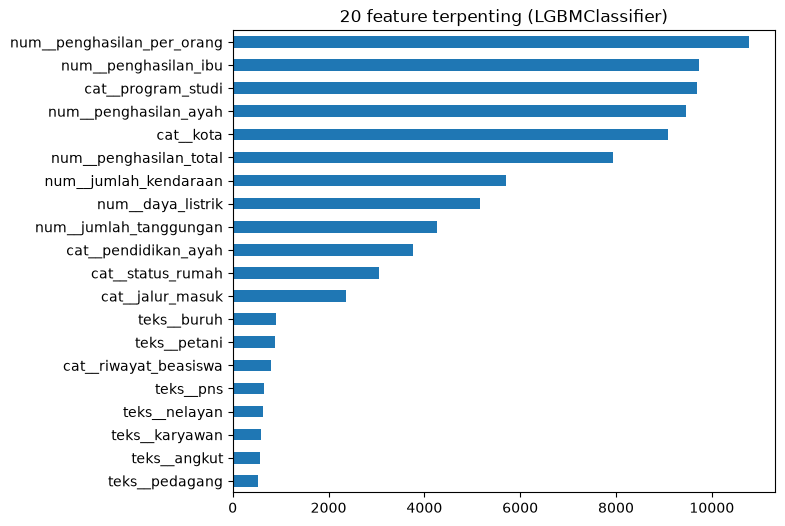

In [12]:
pipe.fit(X, y)
feature_names = pipe[0].get_feature_names_out()
importance = pd.Series(pipe[-1].feature_importances_, index=feature_names)
importance = importance.sort_values()
importance.tail(20).plot.barh(figsize=(7, 6))
plt.title(f"20 feature terpenting ({MODEL_NAME})")
plt.show()

test_proba = pipe.predict_proba(test[X.columns])
np.save(f"test_{MODEL_NAME}.npy", test_proba)

## Submission

In [13]:
predictions = CLASSES[(test_proba * class_weights).argmax(axis=1)]

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["kelas_ukt"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,kelas_ukt
0,30381,2
1,30382,3
2,30383,2
3,30384,2
4,30385,5
